<h1>Burst Kinetics</h1>
<p>G. Woehlke 2016 ff (converted from Wolfram Mathematica, aided by A.I.)</p>

<p>Time trace of product formation in an enzyme with fast binding and rate-limiting product release.</p>
<p><img src="2-15_BurstKinetics.png" width="466"> </p>
<p><ul>
    <li>E	enzyme
    <li>A	substrate A
    <li>EA	enzyme-substrate complex
    <li>EP	enzyme-product complex
    <li>P	Product
</ul></p>
<p>The set of equations is: 
    <ul>
        <li>$\text{cE}'(t)=\text{cA} (-\text{k12}) \text{cE}(t)+\text{k21} \text{cEA}(t)+\text{k34} \text{cEP}(t)$</li>
        <li>$\text{cEA}'(t)=\text{cA} (+\text{k12}) \text{cE}(t)-\text{k21} \text{cEA}(t)-\text{k23} \text{cEA}(t)$</li>
        <li>$\text{cEP}'(t)=+\text{k23} \text{cEA}(t)-\text{k34} \text{cEP}(t)$</li>
        <li>$\text{cP}'(t)=+\text{k34} \text{cEP}(t)$</li>
    </ul></p>
<p>The system can be solved analytically or numerically. </p>
<p>For background information see also p. 274ff chapter 11.2 in: Cornish-Bowden, A., 1995. Fundamentals of Enzyme Kinetics, Revised edition. ed. Portland Press, London.
</p>

<h3>1. Numerical solution of the kinetic scheme</h3>
<p>The code below uses the module <i>SciPy</i> to integrate the time trace over a given range: </p>
 <p style="font-family:courier">from scipy.integrate import solve_ivp</p>    

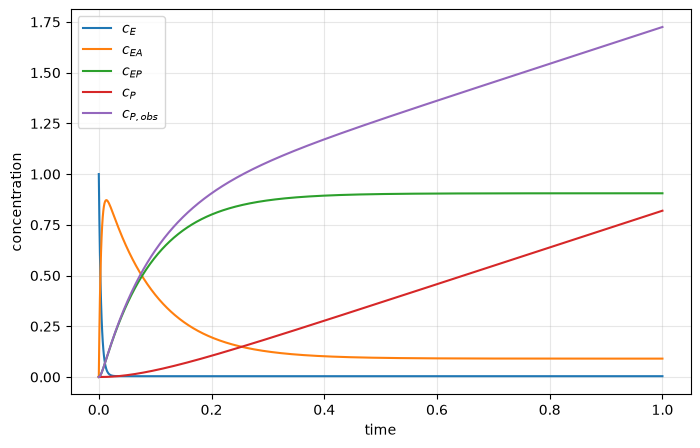

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# ============================================================
# Burst reaction
#
# E + A  <-->  EA  -->  EP  -->  E + P
#      k12     k21    k23     k34
#
# A is assumed to be in large excess, so cA is constant.
# ============================================================


# ------------------------------------------------------------
# Rate constants and concentrations
# Replace these example values by your experimental values.
# ------------------------------------------------------------

k12 = 1.0       # concentration^-1 time^-1
k21 = 1.0       # time^-1
k23 = 10.0       # time^-1
k34 = 1.0       # time^-1

cA = 250.0       # constant substrate concentration

cE0  = 1.0      # initial free enzyme concentration
cEA0 = 0.0
cEP0 = 0.0
cP0  = 0.0


# ------------------------------------------------------------
# Differential equations
# y = [cE, cEA, cEP, cP]
# ------------------------------------------------------------

def burst_odes(t, y, k12, k21, k23, k34, cA):

    cE, cEA, cEP, cP = y

    dcE_dt = -k12 * cE * cA + k21 * cEA + k34 * cEP

    dcEA_dt = (
        +k12 * cE * cA
        -k21 * cEA
        -k23 * cEA
    )

    dcEP_dt = (
        +k23 * cEA
        -k34 * cEP
    )

    dcP_dt = +k34 * cEP

    return [dcE_dt, dcEA_dt, dcEP_dt, dcP_dt]


# ------------------------------------------------------------
# Initial conditions
# Mathematica equivalent:
# intermeds = {cE[t], cEA[t], cEP[t], cP[t]}
# ------------------------------------------------------------

y0 = [cE0, cEA0, cEP0, cP0]


# ------------------------------------------------------------
# Time range
# ------------------------------------------------------------

t_start = 0.0
t_end = 1.0

t_eval = np.linspace(t_start, t_end, 1000)


# ------------------------------------------------------------
# Numerical solution
# ------------------------------------------------------------

sol = solve_ivp(
    burst_odes,
    (t_start, t_end),
    y0,
    t_eval=t_eval,
    args=(k12, k21, k23, k34, cA),
    method="LSODA",
    rtol=1e-9,
    atol=1e-12
)


# ------------------------------------------------------------
# Extract concentrations
# ------------------------------------------------------------

t = sol.t

cE  = sol.y[0]
cEA = sol.y[1]
cEP = sol.y[2]
cP  = sol.y[3]
cP_obs = cEP + cP

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(t, cE,  label=r"$c_E$")
plt.plot(t, cEA, label=r"$c_{EA}$")
plt.plot(t, cEP, label=r"$c_{EP}$")
plt.plot(t, cP,  label=r"$c_P$")
plt.plot(t, cP_obs,  label=r"$c_{P,obs}$")


plt.xlabel("time")
plt.ylabel("concentration")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

<h3>Figure legend</h3>
<p>Time trace of burst kinetics. Scheme:</p>
<p><img src="2-15_BurstKinetics.png" width="466"> </p>

<h3>2. Analytical solution</h3>
<p>Matrix algebra provides suitable method for the analytical solution of the problem. With the above reaction scheme:</p>
<p><img src="2-15_BurstKinetics.png" width="466"> </p>
<p>... we get an enzyme state vector is $c(t) = \left( \begin{array}{r}
c_{E}  \\
c_{EA}  \\
c_{EP}  \\
c_{P}    \\
\end{array} \right) $ and</p>
<p>$\frac{dc}{dt} = M \cdot c $ with </p>
<p>$M = \left( \begin{array}{rrrr}
-k_{12} c_A & k_{12}             & k_{34}  & 0 \\
 k_{12} c_A & -(k_{21} + k_{23}) & 0       & 0 \\
 0          & k_{23}             & -k_{34} & 0 \\
 0          & 0                  & k_{34}  & 0  \\
\end{array} \right) $</p>
<p>The exact solution is consequentially $c(t) = e^{M t} c(0)$. <i>SymPy</i> notation:</p>

In [ ]:
import sympy as sp

t = sp.symbols('t', real=True, nonnegative=True)

k12, k21, k23, k34, cA = sp.symbols(
    'k12 k21 k23 k34 cA',
    positive=True
)

M = sp.Matrix([
    [-k12*cA,      k21,       k34, 0],
    [ k12*cA, -(k21+k23),        0, 0],
    [       0,      k23,     -k34, 0],
    [       0,        0,       k34, 0]
])

# Initial concentrations:
# cE(0)=1, cEA(0)=0, cEP(0)=0, cP(0)=0
c0 = sp.Matrix([1, 0, 0, 0])

# Exact analytical solution
ct = sp.exp(M*t) * c0

cE_sol  = sp.simplify(ct[0])
cEA_sol = sp.simplify(ct[1])
cEP_sol = sp.simplify(ct[2])
cP_sol  = sp.simplify(ct[3])

In [ ]:
sp.pprint(cE_sol)

In [ ]:
cBurst_sol = sp.simplify(cEP_sol + cP_sol)

In [ ]:
cBurst_sol = sp.integrate(
    k23 * cEA_sol,
    (t, 0, t)
)

In [ ]:
tau = sp.symbols('tau', nonnegative=True)

cBurst_sol = sp.integrate(
    k23 * cEA_sol.subs(t, tau),
    (tau, 0, t)
)

cBurst_sol = sp.simplify(cBurst_sol)

<h3>Simplification: </h3>
<p>There is a simplification that reduces the system to a 3x3 matrix. We noted above that $c_{burst}(t) = c_{EP}(t) + c_{P}(t)$. The matrix multiplication</p>
<p>$\left( \begin{array}{r}
    \dot{c_{E}}  \\
    \dot{c_{EA}}  \\
    \dot{c_{EP}}  \\
    \end{array} \right) = 
    \left( \begin{array}{rrr}
       -\alpha & k_{21} & k_{34} \\
       \alpha & -\left( k_{21} + k_{23} \right) & 0 \\
       0 & k_{23} & -k_{34} \\
    \end{array} \right) 
    \left( \begin{array}{r}
    c_{E}  \\
    c_{EA}  \\
    c_{EP}  \\
    \end{array} \right)$ with $\alpha = k{12} c_A$ gives</p>

<p>$\left( \begin{array}{r}
       - c_E \alpha + c_{EA} k_{12} + c_{EP} k_{34}  \\
       + c_E \alpha + c_{EA} \left( -k_{21} - k_{23} \right)   \\
       c_{EA} k_{23} - c_{EP} k_{34}  \\
    \end{array} \right)$</p>
<p>Check this in the reaction scheme:</p>
<p><img src="2-15_BurstKinetics.png" width="466"> </p>

<p>The third row of the solution vector tells us the concentration of EP, $c_{EP}(t) = k_{23} c_{EA}(t) - k_{34} c_{EP}(t)$ . We get the burst rate by adding this concentration $c_{EP}(t) $ and the product concentration , which is $c_{P}(t)= k_{34} c_{EP}(t)$. Thus we find the burst rate: $\frac{d{c_{burst}}}{dt}
    = \left( c_{EA} k_{23} - c_{EP} k_{34} \right) + c_{EP} k_{34}
    = c_{EA} k_{23}  $.</p>
<p>To get the burst kinetics, we now need to solve this 3x3 matrix. The general solution of this ODE has the form 
$c_{EP}(t) + c_{P}(t) = v_{steady-st} + A_0 + A_1 e^{-\lambda_1 t} + A_2 e^{-\lambda_2 t}$ </p>

<h3>Calulation of amplitudes and rates</h3>
<p>For clearer visibility, we abbreviate  $\alpha = k_{12} c_A$, $\beta = k_{12}$, $\gamma = k_{23}$, $\delta = k_{34}$. </p>
<p>Moreover, the intermediate concentration vector is 
    $x(t) = \left( \begin{array}{r}
       c_{E}  \\
       c_{EA}  \\
       c_{EP}  \\
    \end{array} \right)$</p>
<p>The rate of concentration flow will therefore be determined by the transition rate matrix M 
    $ \frac{dx}{dt} = M x$, in our kinetic scheme </p>

<p>    $M = \left( \begin{array}{rrr}
\alpha & \beta & \delta \\
\alpha & -\left( \beta + \delta \right) & 0 \\
0 & \gamma & -\delta \\
\end{array} \right) $. We thus have to solve the following rate equation: </p>

<p>    $M x = \left( \begin{array}{rrr}
\alpha & \beta & \delta \\
\alpha & -\left( \beta + \delta \right) & 0 \\
0 & \gamma & -\delta \\
\end{array} \right) 
    \left( \begin{array}{r}
    c_{E}  \\
    c_{EA}  \\
    c_{EP}  \\
    \end{array} \right)$</p>

<p>In our example, we assume the iniitial condition $x(0) = \left( \begin{array}{r}
1  \\
0  \\
0  \\
\end{array} \right) $, $c_{E}(0) = 1$, others zero, i.e. all enzyme is present in a ligand- and product-free state).</p>

<h3>2.1. Eigenvalue calculus</h3>
<p>We are now in a position to solve the system using linear algebra. The characteristic polynomial factorizes to</p>
<p>$\det(\lambda I - M) = \lambda (\lambda^2 + S \lambda + Q)$, where</p>
<p>$I$ identity matrix,</p>
<p>$S = \alpha + \beta + \gamma + \delta$, and </p>
<p> $Q = \alpha \gamma + \alpha \delta + \beta \delta + \gamma \delta$. 
    The eigenvalues are</p>
<p>$\lambda_0 = 0$ ($\lambda$ in front of the brackets) and</p>
<p>$\lambda_{1,2} = - \frac{S ± \sqrt{S^2 - 4 Q}}{2}$ (solutions of the quadratic equation).</p>
<p>The zero eigenvector is a consequence of enzyme conservation: </p>
<p>$c_E + c_{EA} + c_{EP} = 1$. In <i>SymPy</i>: </p>

In [ ]:
import sympy as sp

# ------------------------------------------------------------
# Symbols
# ------------------------------------------------------------

t = sp.symbols('t', nonnegative=True, real=True)

k12, k21, k23, k34, cA = sp.symbols(
    'k12 k21 k23 k34 cA',
    positive=True
)

alpha_s = k12*cA
beta_s  = k21
gamma_s = k23
delta_s = k34


# ------------------------------------------------------------
# Enzyme-state matrix
# ------------------------------------------------------------

M3_sym = sp.Matrix([
    [-alpha_s,        beta_s,       delta_s],
    [ alpha_s, -(beta_s+gamma_s),         0],
    [     0,       gamma_s,      -delta_s]
])

M3_sym

In [ ]:
lam_s = sp.symbols('lambda')

charpoly3 = sp.factor(
    M3_sym.charpoly(lam_s).as_expr()
)

charpoly3

In [ ]:
import sympy as sp
from IPython.display import display

lam_s = sp.symbols("lambda")
alpha_s, beta_s, gamma_s, delta_s = sp.symbols(
    "alpha beta gamma delta",
    positive=True
)

M3_sym = sp.Matrix([
    [-alpha_s,  beta_s,             delta_s],
    [ alpha_s, -(beta_s + gamma_s),       0],
    [       0, gamma_s,            -delta_s]
])

assert M3_sym.shape == (3, 3)

charpoly3 = sp.factor(
    M3_sym.charpoly(lam_s).as_expr()
)

display(charpoly3)

<p>Solution of the quadratic equation, using smart substitutions:</p>

In [ ]:
S = sp.simplify(alpha_s + beta_s + gamma_s + delta_s)

Q = sp.simplify(
    alpha_s*gamma_s
    + alpha_s*delta_s
    + beta_s*delta_s
    + gamma_s*delta_s
)

Delta = sp.simplify(S**2 - 4*Q)

r1 = sp.simplify((S + sp.sqrt(Delta))/2)
r2 = sp.simplify((S - sp.sqrt(Delta))/2)

print("r1 =")
sp.pprint(r1)

print("\nr2 =")
sp.pprint(r2)

<h3>2. The zero-Eigenvalue state is the steady state enzyme distribution</h3>

In [ ]:
cE_ss  = sp.simplify(delta_s*(beta_s + gamma_s) / Q)
cEA_ss = sp.simplify(alpha_s*delta_s / Q)
cEP_ss = sp.simplify(alpha_s*gamma_s / Q)

sp.simplify(cE_ss + cEA_ss + cEP_ss)

In [ ]:
A1 = sp.simplify(
    (r2*cEA_ss - alpha_s)/(r1-r2)
)

A2 = sp.simplify(
    (alpha_s - r1*cEA_ss)/(r1-r2)
)

cEA_analytic = sp.simplify(
    cEA_ss
    + A1*sp.exp(-r1*t)
    + A2*sp.exp(-r2*t)
)

cEA_analytic

<h3>4. Analytical burst equation</h3>

In [ ]:
v_ss = sp.simplify(gamma_s*cEA_ss)

burst = sp.simplify(
    v_ss*t
    + gamma_s*A1/r1 * (1 - sp.exp(-r1*t))
    + gamma_s*A2/r2 * (1 - sp.exp(-r2*t))
)

burst

<h3>5. Put the burst equation into the familiar kinetic form</h3>

In [ ]:
B1 = sp.simplify(gamma_s*A1/r1)
B2 = sp.simplify(gamma_s*A2/r2)

B_inf = sp.factor(B1 + B2)

B_inf

<h3>6. Entire compact IPython analytical calculation</h3>

In [ ]:
import sympy as sp

# ============================================================
# Analytical burst kinetics using eigenvalues
# ============================================================

t = sp.symbols('t', nonnegative=True, real=True)

k12, k21, k23, k34, cA = sp.symbols(
    'k12 k21 k23 k34 cA',
    positive=True
)

# Pseudo-first-order notation
alpha = k12*cA
beta  = k21
gamma = k23
delta = k34


# ------------------------------------------------------------
# Enzyme-state matrix
# ------------------------------------------------------------

M = sp.Matrix([
    [-alpha,        beta,       delta],
    [ alpha, -(beta+gamma),         0],
    [     0,       gamma,      -delta]
])

x0 = sp.Matrix([1, 0, 0])


# ------------------------------------------------------------
# Characteristic polynomial
# ------------------------------------------------------------

lam = sp.symbols('lambda')

charpoly = sp.factor(M.charpoly(lam).as_expr())

print("Characteristic polynomial:")
sp.pprint(charpoly)


# ------------------------------------------------------------
# Eigenvalue parameters
# ------------------------------------------------------------

S = alpha + beta + gamma + delta

Q = (
    alpha*gamma
    + alpha*delta
    + beta*delta
    + gamma*delta
)

Delta = sp.simplify(S**2 - 4*Q)

r1 = sp.simplify((S + sp.sqrt(Delta))/2)
r2 = sp.simplify((S - sp.sqrt(Delta))/2)


# eigenvalues:
lambda0 = 0
lambda1 = -r1
lambda2 = -r2


# ------------------------------------------------------------
# Steady-state enzyme concentrations
# ------------------------------------------------------------

cE_ss  = sp.simplify(delta*(beta+gamma)/Q)
cEA_ss = sp.simplify(alpha*delta/Q)
cEP_ss = sp.simplify(alpha*gamma/Q)


# ------------------------------------------------------------
# EA transient coefficients
# ------------------------------------------------------------

A1 = sp.simplify(
    (r2*cEA_ss - alpha)/(r1-r2)
)

A2 = sp.simplify(
    (alpha - r1*cEA_ss)/(r1-r2)
)


# ------------------------------------------------------------
# Analytical cEA(t)
# ------------------------------------------------------------

cEA = sp.simplify(
    cEA_ss
    + A1*sp.exp(-r1*t)
    + A2*sp.exp(-r2*t)
)


# ------------------------------------------------------------
# Steady-state product rate
# ------------------------------------------------------------

v_ss = sp.simplify(gamma*cEA_ss)


# ------------------------------------------------------------
# Observed product = cEP + cP
# ------------------------------------------------------------

burst = sp.simplify(
    v_ss*t
    + gamma*A1/r1*(1-sp.exp(-r1*t))
    + gamma*A2/r2*(1-sp.exp(-r2*t))
)


# ------------------------------------------------------------
# Long-time burst amplitude
# ------------------------------------------------------------

B_inf = sp.factor(
    gamma*A1/r1 + gamma*A2/r2
)


print("\nr1:")
sp.pprint(r1)

print("\nr2:")
sp.pprint(r2)

print("\nSteady-state rate:")
sp.pprint(v_ss)

print("\nBurst amplitude:")
sp.pprint(B_inf)

print("\nObserved product cEP + cP:")
sp.pprint(burst)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display

In [ ]:
def burst_solution(t, k12, k21, k23, k34, cA):

    # Pseudo-first-order rate constant
    alpha = k12 * cA

    beta  = k21
    gamma = k23
    delta = k34

    # Characteristic polynomial:
    #
    # lambda (lambda^2 + S lambda + Q) = 0

    S = alpha + beta + gamma + delta

    Q = (
        alpha*gamma
        + alpha*delta
        + beta*delta
        + gamma*delta
    )

    discriminant = S**2 - 4*Q

    # scimath.sqrt also works if the eigenvalues become complex
    root = np.lib.scimath.sqrt(discriminant)

    r1 = (S + root) / 2
    r2 = (S - root) / 2

    # Steady-state EA concentration
    cEA_ss = alpha * delta / Q

    # Coefficients of the two exponential modes
    A1 = (r2*cEA_ss - alpha) / (r1-r2)
    A2 = (alpha - r1*cEA_ss) / (r1-r2)

    # Steady-state product formation rate
    v_ss = gamma * cEA_ss

    # Measured product:
    # B(t) = cEP(t) + cP(t)
    B = (
        v_ss*t
        + gamma*A1/r1 * (1 - np.exp(-r1*t))
        + gamma*A2/r2 * (1 - np.exp(-r2*t))
    )

    # Burst amplitude = intercept of long-time asymptote
    B_inf = gamma*A1/r1 + gamma*A2/r2

    # Numerical roundoff can leave tiny imaginary components
    B = np.real_if_close(B)
    B_inf = np.real_if_close(B_inf)
    r1 = np.real_if_close(r1)
    r2 = np.real_if_close(r2)

    return B, v_ss, B_inf, r1, r2

In [ ]:
def plot_burst(
    k12=1.0,
    k21=0.2,
    k23=2.0,
    k34=0.1,
    cA=10.0,
    tmax=30.0
):

    t = np.linspace(0, tmax, 1000)

    B, v_ss, B_inf, r1, r2 = burst_solution(
        t, k12, k21, k23, k34, cA
    )

    # Long-time asymptote
    B_asym = B_inf + v_ss*t

    fig, ax = plt.subplots(figsize=(8, 5))

    # Experimental observable
    ax.plot(
        t, B,
        linewidth=2.5,
        label=r"$[EP]+[P]$"
    )

    # Steady-state extrapolation
    ax.plot(
        t, B_asym,
        "--",
        linewidth=1.8,
        label=r"$B_\infty + v_{ss}t$"
    )

    # Burst amplitude
    ax.plot(
        0, B_inf,
        "o",
        label=rf"$B_\infty={float(np.real(B_inf)):.3f}$"
    )

    ax.set_xlabel("time")
    ax.set_ylabel(r"observed product $[EP]+[P]$")

    ax.set_xlim(0, tmax)
    ax.set_ylim(bottom=0)

    ax.grid(alpha=0.3)
    ax.legend()

    # Kinetic information inside the figure
    text = (
        rf"$k_{{12}}[A]={k12*cA:.3g}$" "\n"
        rf"$r_1={float(np.real(r1)):.3g}$" "\n"
        rf"$r_2={float(np.real(r2)):.3g}$" "\n"
        rf"$v_{{ss}}={v_ss:.3g}$" "\n"
        rf"$B_\infty={float(np.real(B_inf)):.3g}$"
    )

    ax.text(
        0.98, 0.05,
        text,
        transform=ax.transAxes,
        horizontalalignment="right",
        verticalalignment="bottom",
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            alpha=0.8
        )
    )

    plt.show()

In [ ]:
plot_burst()

<h3>Figure legend</h3>
<p><img src="2-15_BurstKinetics.png" width="466"> </p>

In [ ]:
k12_slider = widgets.FloatLogSlider(
    value=1.0,
    base=10,
    min=-2,
    max=2,
    step=0.05,
    description="k12",
    continuous_update=False
)

k21_slider = widgets.FloatLogSlider(
    value=0.2,
    base=10,
    min=-3,
    max=1,
    step=0.05,
    description="k21",
    continuous_update=False
)

k23_slider = widgets.FloatLogSlider(
    value=2.0,
    base=10,
    min=-2,
    max=2,
    step=0.05,
    description="k23",
    continuous_update=False
)

k34_slider = widgets.FloatLogSlider(
    value=0.1,
    base=10,
    min=-3,
    max=1,
    step=0.05,
    description="k34",
    continuous_update=False
)

cA_slider = widgets.FloatLogSlider(
    value=10.0,
    base=10,
    min=-1,
    max=3,
    step=0.05,
    description="[A]",
    continuous_update=False
)

tmax_slider = widgets.FloatSlider(
    value=30.0,
    min=1,
    max=100,
    step=1,
    description="t max",
    continuous_update=False
)

In [ ]:
interactive_plot = widgets.interactive(
    plot_burst,
    k12=k12_slider,
    k21=k21_slider,
    k23=k23_slider,
    k34=k34_slider,
    cA=cA_slider,
    tmax=tmax_slider
)

display(interactive_plot)

<h3>Figure legend</h3>
<p>Time trace of a kinetic burst. Scheme:</p>
<p><img src="2-15_BurstKinetics.png" width="466"> </p>